# Problem Analysis Workshop B — K-Means Clustering

**Course:** PROG8431 — Data Analysis, Mathematics, Modeling and Algorithms

**Team Members:**
- Ubaid Ullah — 9110715
- Rangeetha — 9081357
- Koushik Balne — 9087547

## 1. Project Overview

This workshop continues our Crop Recommendation Analysis project from Assignments 1 and 2.

We will apply K-Means clustering to identify groups of similar growing conditions in our existing dataset. We will examine the resulting clusters and investigate how crop labels are distributed across them.

**Selected clustering variables:** Rainfall and relative humidity, following the candidate-variable comparison in Section 4.


### 1.1 How Clustering Will Deepen Our Understanding of the Data

In Assignments 1 and 2 we described the variables one at a time and compared **two crops chosen in advance** (rice vs maize rainfall: means of 236.18 mm and 84.77 mm). That approach can only test questions we already thought to ask.

K-Means works the other way round: it **ignores the crop labels** and groups records only by how similar their recorded growing conditions are. This lets us ask new questions:

- **What distinct combinations of rainfall and humidity does the dataset contain?** Instead of 22 separate crop labels, how many groups of conditions are there?
- **Which crop labels are recorded under similar conditions?** If two crops' records fall in the same cluster, they share similar humidity and rainfall *in this dataset*. That is a lead for further investigation, not evidence that one crop could replace the other.
- **Do crops we think of as similar actually share conditions?** For example, do all the pulses end up together?
- **Do the other variables differ between clusters?** We profile nitrogen, phosphorus, potassium, temperature and pH inside clusters built from only two variables.

## 2.Setup and Configuration

In [1]:

# Step 2: Setup and Data Loading

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans

# Shared settings used throughout the notebook (defined once)

NUMERIC_COLS = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
LABELS = {"N": "Nitrogen (ratio)", "P": "Phosphorus (ratio)", "K": "Potassium (ratio)",
          "temperature": "Temperature (°C)", "humidity": "Relative Humidity (%)",
          "ph": "Soil pH", "rainfall": "Rainfall (mm)"}


DATA_PATH = Path("Crop_recommendation.csv")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Dataset shape: (2200, 8)
Column names: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



## 3. Data Cleaning and Quality Assessment

Before applying K-Means clustering, we must verify that our dataset is suitable for analysis.

We will examine:
- Missing values and duplicate records.
- Data types and the number of unique crop labels.
- Invalid or unexpected numerical values.
- The distribution of records across crop categories.

We will preserve the original observations unless a clearly justified data-quality issue requires correction.

**Purpose:** Ensure that our clustering analysis uses reliable, consistent data without making unnecessary changes to the dataset.


In [2]:

# Step 3: Data Quality Assessment

clean_df = df.copy()

print("=== Missing Values ===")
print(clean_df.isnull().sum())

print("\n=== Duplicate Records ===")
print("Total duplicates:", clean_df.duplicated().sum())

print("\n=== Data Types ===")
print(clean_df.dtypes)

print("\n=== Crop Categories ===")
print("Unique crop types:", clean_df["label"].nunique())
print(clean_df["label"].value_counts().sort_index())

print("\n=== Numerical Data Quality ===")
print("Negative nutrient values:",
      (clean_df[["N", "P", "K"]] < 0).sum().sum())

print("Negative rainfall values:",
      (clean_df["rainfall"] < 0).sum())

print("Humidity outside 0–100%:",
      ((clean_df["humidity"] < 0) |
       (clean_df["humidity"] > 100)).sum())

print("pH outside 0–14:",
      ((clean_df["ph"] < 0) |
       (clean_df["ph"] > 14)).sum())


=== Missing Values ===
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

=== Duplicate Records ===
Total duplicates: 0

=== Data Types ===
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

=== Crop Categories ===
Unique crop types: 22
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

=== Numerical Data Quality ===
Negative nutrient values: 0
Negati


### Data Quality Findings

The dataset contains 2,200 observations across 22 crop categories, with 100 records per crop.

We found no missing values, exact duplicate records, negative nutrient or rainfall values, or humidity and pH values outside their expected ranges.

All seven environmental and soil variables are numerical, while the crop label is categorical.

**Outliers**: outliers are assessed with box plots in Section 4 (Table 1A). They come from specific crops (for example rice for high rainfall and chickpea for low humidity), so they are real crop profiles, not errors. Deleting them would delete whole crop types, so **all 2,200 records are kept**. The rainfall outliers also matter for the scaling choice in Section 5.

No records were removed or modified. We retained the original measurements for the clustering analysis.


## 4. Exploratory Data Analysis (EDA)

We examine the distributions and variability of **rainfall and relative humidity**, the two variables selected for the final clustering analysis. We also include **temperature** as an alternative candidate so the variable-selection decision can be explained using evidence.

Our analysis focuses on:

- **Rainfall (mm):** Rainfall values recorded in the dataset.
- **Relative humidity (%):** Recorded atmospheric moisture conditions.
- **Temperature (°C):** An alternative environmental variable used in the candidate-pair comparison.
- **Variability and visual patterns:** Whether the observations contain distinct concentrations worth exploring with K-Means.

The descriptive statistics and histograms cover all three candidates; the box plots focus on rainfall and humidity, while Section 4.2 compares rainfall–temperature with rainfall–humidity.

**Note:** The dataset does not specify the rainfall accumulation period, so rainfall values will not be interpreted as annual rainfall or irrigation requirements.


In [3]:
# Step 4: Descriptive Statistics for Candidate Variables

candidate_features = ["rainfall", "humidity", "temperature"]

summary = clean_df[candidate_features].describe().T

# Improve readability for notebook presentation
summary = summary.rename(columns={
    "count": "Records",
    "mean": "Mean",
    "std": "Std. Deviation",
    "min": "Minimum",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Maximum"
})

summary.index = ["Rainfall (mm)", "Relative Humidity (%)", "Temperature (°C)"]

display(
    summary.style
    .format({
        "Records": "{:,.0f}",
        **{col: "{:,.2f}" for col in summary.columns if col != "Records"}
    })
    .set_caption("Table 1. Descriptive Statistics for Candidate Clustering Variables")
)


,Records,Mean,Std. Deviation,Minimum,Q1,Median,Q3,Maximum
Rainfall (mm),"2,200",103.46,54.96,20.21,64.55,94.87,124.27,298.56
Relative Humidity (%),"2,200",71.48,22.26,14.26,60.26,80.47,89.95,99.98
Temperature (°C),"2,200",25.62,5.06,8.83,22.77,25.60,28.56,43.68


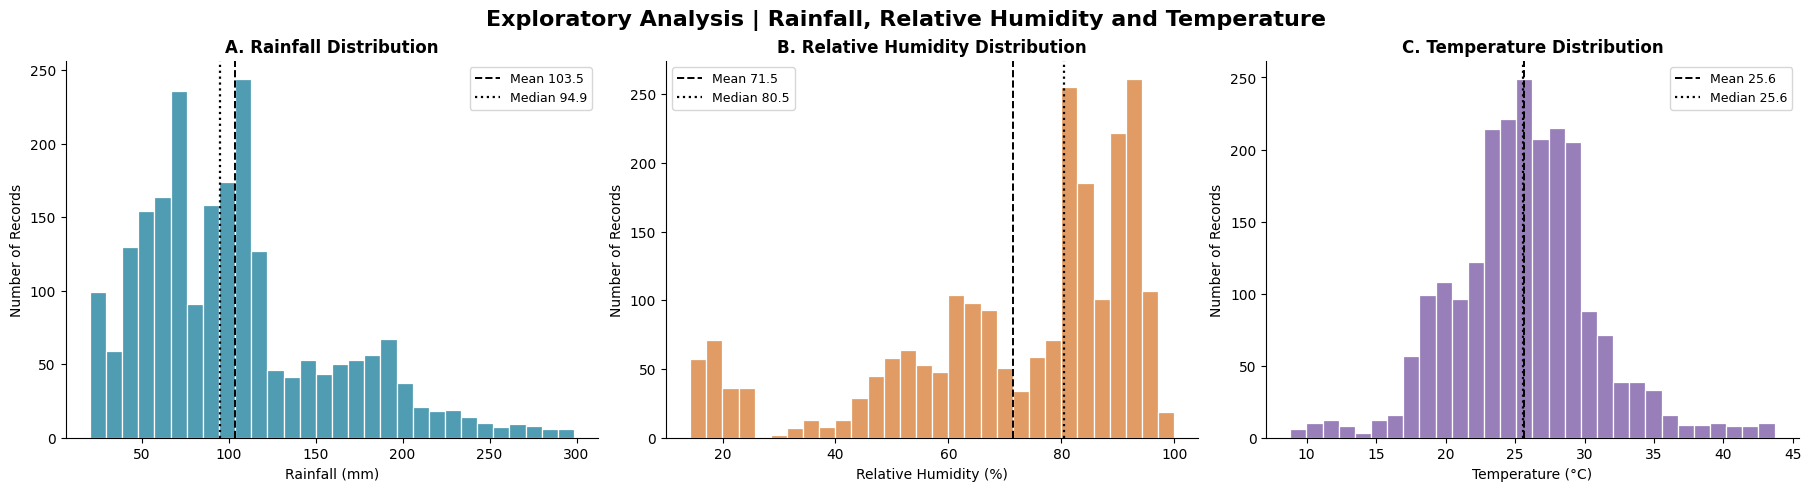

In [4]:
# Step 4: Distributions of the Candidate Variables (rainfall, humidity and temperature)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), layout="constrained")

histograms = [
    ("rainfall", "A. Rainfall Distribution", "Rainfall (mm)", "#167D9A"),
    ("humidity", "B. Relative Humidity Distribution", "Relative Humidity (%)", "#D77B32"),
    ("temperature", "C. Temperature Distribution", "Temperature (°C)", "#7654A3"),
]

for ax, (variable, title, xlabel, color) in zip(axes, histograms):
    sns.histplot(
        data=clean_df,
        x=variable,
        bins=30,
        color=color,
        edgecolor="white",
        ax=ax
    )
    # Mean and median lines make the skew visible
    ax.axvline(clean_df[variable].mean(), color="black", linestyle="--", linewidth=1.4,
               label=f"Mean {clean_df[variable].mean():.1f}")
    ax.axvline(clean_df[variable].median(), color="black", linestyle=":", linewidth=1.6,
               label=f"Median {clean_df[variable].median():.1f}")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of Records")
    ax.legend(fontsize=9)

fig.suptitle(
    "Exploratory Analysis | Rainfall, Relative Humidity and Temperature",
    fontsize=16,
    fontweight="bold"
)

sns.despine()
plt.show()

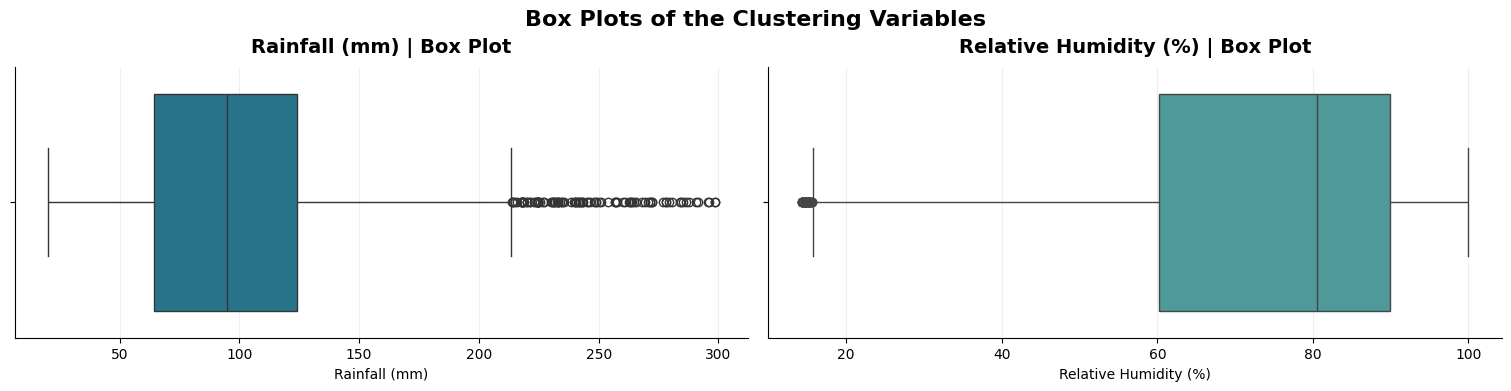

,Q1,Median,Q3,Lower Fence,Upper Fence,Outliers,Outlier Crops
Rainfall (mm),64.55,94.87,124.27,-25.02,213.84,100,"rice (68), papaya (17), coconut (15)"
Relative Humidity (%),60.26,80.47,89.95,15.73,134.48,30,chickpea (30)


In [5]:
# Step 4.1: Rainfall and humidity box plots (outlier assessment for the two clustering variables)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), layout="constrained")



for ax, variable, color in zip(axes, ["rainfall", "humidity"], ["#167D9A", "#42A5A5"]):
    sns.boxplot(x=clean_df[variable], color=color, ax=ax)
    ax.set_title(f"{LABELS[variable]} | Box Plot", fontsize=14, fontweight="bold", pad=10)
    ax.set_xlabel(LABELS[variable])
    ax.grid(axis="x", alpha=0.2)
    sns.despine(ax=ax)

fig.suptitle("Box Plots of the Clustering Variables", fontsize=16, fontweight="bold")
plt.show()

# Exact box-plot values, so the interpretation below is calculated rather than read by eye
q1 = clean_df[NUMERIC_COLS].quantile(0.25)
q3 = clean_df[NUMERIC_COLS].quantile(0.75)
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier_mask = (clean_df[NUMERIC_COLS] < lower_fence) | (clean_df[NUMERIC_COLS] > upper_fence)
box_stats = pd.DataFrame({
    LABELS[v]: {
        "Q1": clean_df[v].quantile(0.25),
        "Median": clean_df[v].median(),
        "Q3": clean_df[v].quantile(0.75),
        "Lower Fence": lower_fence[v],
        "Upper Fence": upper_fence[v],
        "Outliers": int(outlier_mask[v].sum()),
        "Outlier Crops": ", ".join(f"{c} ({n})" for c, n in
                                   clean_df.loc[outlier_mask[v], "label"].value_counts().head(3).items()),
    } for v in ["rainfall", "humidity"]
}).T

display(box_stats.style.format({"Q1": "{:.2f}", "Median": "{:.2f}", "Q3": "{:.2f}",
                                "Lower Fence": "{:.2f}", "Upper Fence": "{:.2f}", "Outliers": "{:.0f}"})
        .set_caption("Table 1A. Box-Plot Values and Outlier Crops for Rainfall and Humidity"))

### Box Plot Interpretation: Rainfall and Humidity

**Rainfall**

- **Median:** 94.87 mm; the middle 50 % of records lies between 64.55 and 124.27 mm.
- **Overall spread:** from 20.21 mm to 298.56 mm. The long right whisker and the **100 high outliers above 213.84 mm** show that rainfall is right-skewed.
- **Outliers:** mainly rice (68), with papaya (17) and coconut (15) (Table 1A). They are real wet-climate crop records, so they are kept.

**Relative humidity**

- **Median:** 80.47 %; the middle 50 % of records lies between 60.26 % and 89.95 %, so most records are humid.
- **Overall spread:** from 14.26 % to 99.98 %, a wide range of humidity conditions.
- **Outliers:** **30 low outliers below 15.73 %, and all 30 are chickpea** records (Table 1A), an early hint that the driest records may form their own group.

**Interpretation:** The two variables are skewed in opposite directions: rainfall has a long tail of very wet records, while humidity has a small group of very dry ones. Both sets of outliers belong to specific crops, so we keep them. This matters for Section 5: Min-Max scaling is set by the most extreme values, which is one reason we prefer Z-score. The box plots alone do not establish cluster quality, which is assessed in Section 6.


### 4.1 Exploratory Findings and Interpretation

The rainfall histogram shows a right-skewed distribution, with many observations concentrated at lower to moderate rainfall values and fewer observations at higher rainfall levels.

The relative-humidity histogram shows how observations are distributed across lower and higher humidity conditions. Together with the descriptive statistics, it provides a direct examination of both variables used in the final clustering model.

The temperature histogram is roughly symmetric: the mean (25.62 °C) and median (25.60 °C) are almost equal, with a single peak. Unlike humidity, it shows no separate groups of records.

Temperature remains useful as an alternative candidate, rather than a final clustering input. Section 4.2 compares rainfall–temperature and rainfall–humidity scatter plots to support the variable-selection decision.

**Preliminary finding:** Variability and visible concentrations motivate testing K-Means, but distributions alone do not establish a correct number of clusters.



### 4.2 Comparing Candidate Variable Pairs

Two possible variable combinations are being considered:

1. **Rainfall and Temperature:** To explore clustering patterns across recorded precipitation and thermal conditions.
2. **Rainfall and Humidity:** To explore clustering patterns across precipitation and atmospheric moisture conditions.

Both combinations are relevant to the crop dataset. We will examine their relationships, distributions, and visual patterns before finalizing the clustering variables.

The scatter plots are exploratory; visual appearance alone cannot establish which pair produces the best K-Means solution.


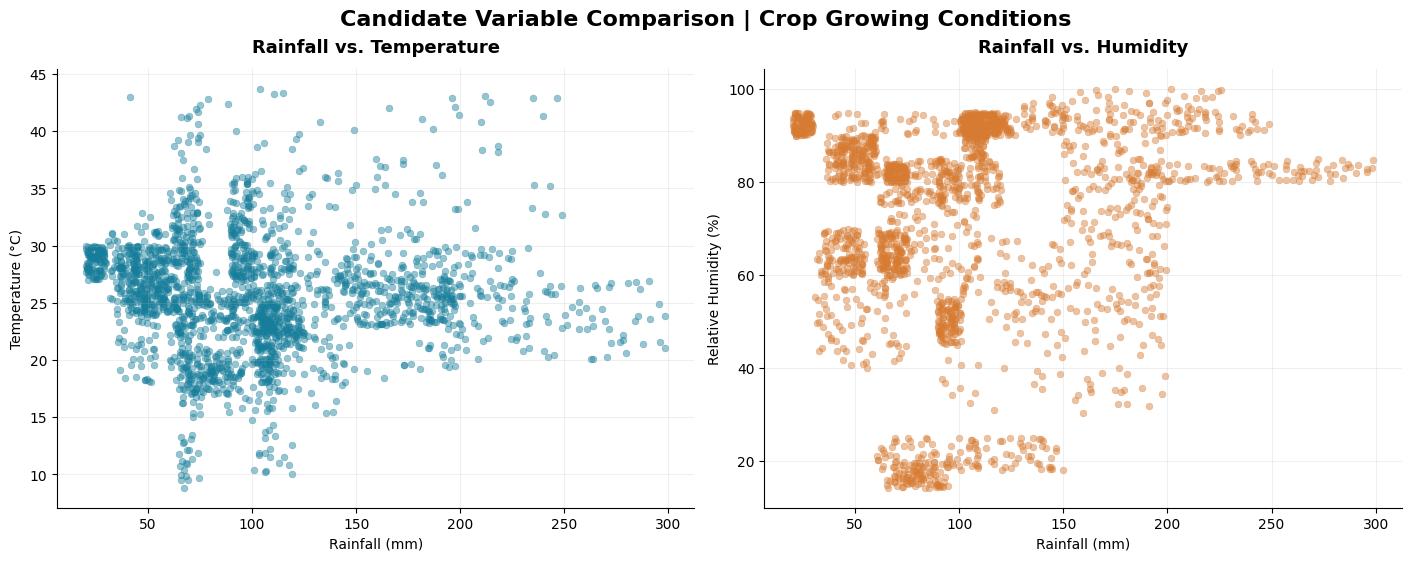

Pearson Correlation with Rainfall
Temperature: -0.030
Humidity:    0.094


In [6]:

# Step 4.2: Compare Candidate Variable Pairs

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5),
    layout="constrained"
)

pairs = [
    ("temperature", "Temperature (°C)", "#167D9A"),
    ("humidity", "Relative Humidity (%)", "#D77B32")
]

for ax, (variable, ylabel, color) in zip(axes, pairs):
    sns.scatterplot(
        data=clean_df,
        x="rainfall",
        y=variable,
        color=color,
        alpha=0.45,
        s=24,
        edgecolor=None,
        ax=ax
    )

    ax.set_title(
        f"Rainfall vs. {variable.title()}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )
    ax.set_xlabel("Rainfall (mm)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    sns.despine(ax=ax)

fig.suptitle(
    "Candidate Variable Comparison | Crop Growing Conditions",
    fontsize=16,
    fontweight="bold"
)

plt.show()

# Quantify the relationships
comparison = clean_df[
    ["rainfall", "temperature", "humidity"]
].corr(method="pearson")

print("Pearson Correlation with Rainfall")
print(f"Temperature: {comparison.loc['rainfall', 'temperature']:.3f}")
print(f"Humidity:    {comparison.loc['rainfall', 'humidity']:.3f}")



### 4.3 EDA Findings and Variable Selection Decision

We compared two candidate variable pairs: rainfall–temperature and rainfall–humidity.

Pearson correlation showed almost no linear relationship between rainfall and temperature (r = -0.030), and a very weak positive relationship between rainfall and humidity (r = 0.094). Neither result establishes the existence or quality of clusters.

The rainfall–humidity scatter plot showed more visually distinct concentrations, particularly at lower and higher humidity levels. This makes the pair useful for exploring differences in moisture-related growing conditions.

**Selected variables:**
- **Rainfall (mm):** Represents recorded precipitation conditions.
- **Humidity (%):** Represents recorded atmospheric moisture conditions.

**Justification:** These two variables are relevant to the project's environmental focus, show potentially interesting groupings, and provide a clear basis for interpreting moisture-related clusters.

The selection is exploratory. Cluster quality will be evaluated after standardization and K-Means rather than inferred from appearance alone.


## 5. Data Transformation and Standardization

### 5.1 Why Standardization Is Necessary

K-Means clustering groups observations based on distances between numerical values. Since rainfall is measured in millimetres and humidity in percentages, their numerical scales differ.

Without standardization, the variable with greater numerical variation may have more influence on the clustering results.

The two methods we have learnt are:

- **Min-Max scaling (`sta01()`):** Transforms each variable to the range 0–1 using its observed minimum and maximum.
- **Z-score standardization (`stamn()`):** Subtracts the variable's mean and divides by its standard deviation, producing mean approximately 0 and standard deviation 1.

We will show both transformations for **rainfall and relative humidity**, then use Z-score for the K-Means model. Z-score gives the two variables comparable variation (unit standard deviations), whereas Min-Max makes their ranges equal. Section 5.5 explains, using our own data, why Z-score is the better choice here.

Original measurements will be preserved for interpreting the final clusters.

In [7]:

# Step 5.2: Z-Score Standardization
# Following the professor's Week 7 stamn() demonstration

def stamn(x):
    return (x - x.mean()) / x.std()


# Keep original measurements unchanged
clustering_df = clean_df.copy()

# Apply Z-score standardization
clustering_df["rainfall_std"] = stamn(clustering_df["rainfall"])
clustering_df["humidity_std"] = stamn(clustering_df["humidity"])

# Create a before-and-after statistical comparison
scaling_summary = pd.DataFrame({
    "Variable": ["Rainfall", "Humidity"],
    "Original Mean": [
        clustering_df["rainfall"].mean(),
        clustering_df["humidity"].mean()
    ],
    "Original Std. Dev.": [
        clustering_df["rainfall"].std(),
        clustering_df["humidity"].std()
    ],
    "Scaled Mean": [
        clustering_df["rainfall_std"].mean(),
        clustering_df["humidity_std"].mean()
    ],
    "Scaled Std. Dev.": [
        clustering_df["rainfall_std"].std(),
        clustering_df["humidity_std"].std()
    ]
})

display(
    scaling_summary.style
    .hide(axis="index")
    .format({
        "Original Mean": "{:.2f}",
        "Original Std. Dev.": "{:.2f}",
        "Scaled Mean": "{:.2f}",
        "Scaled Std. Dev.": "{:.2f}"
    })
    .set_caption("Table 2. Before-and-After Z-Score Standardization")
)


Variable,Original Mean,Original Std. Dev.,Scaled Mean,Scaled Std. Dev.
Rainfall,103.46,54.96,0.00,1.00
Humidity,71.48,22.26,-0.00,1.00


### 5.3 Comparing Min-Max and Z-Score Scaling

The two approaches both remove the original measurement units, but they use different reference points. The table compares the resulting means, standard deviations, and ranges for each selected variable. The following plot shows both methods alongside the original measurements.


In [8]:
# Step 5.3: Compare the Two Scaling Methods Shown in Class
# sta01() is the Min-Max scaling function from the Week 7 demonstration.

def sta01(x):
    return (x - x.min()) / (x.max() - x.min())

# Store the alternative scaling separately; Section 6 still uses Z-scores.
minmax_df = pd.DataFrame({
    "rainfall_minmax": sta01(clean_df["rainfall"]),
    "humidity_minmax": sta01(clean_df["humidity"])
})

scaling_comparison_rows = []
for variable, minmax_col, zscore_col in [
    ("Rainfall", "rainfall_minmax", "rainfall_std"),
    ("Humidity", "humidity_minmax", "humidity_std")
]:
    for method, scaled_values in [
        ("Min-Max", minmax_df[minmax_col]),
        ("Z-score", clustering_df[zscore_col])
    ]:
        scaling_comparison_rows.append({
            "Variable": variable,
            "Method": method,
            "Mean": scaled_values.mean(),
            "Std. Deviation": scaled_values.std(),
            "Minimum": scaled_values.min(),
            "Maximum": scaled_values.max()
        })

scaling_comparison = pd.DataFrame(scaling_comparison_rows)

display(
    scaling_comparison.style
    .hide(axis="index")
    .format({
        "Mean": "{:.3f}",
        "Std. Deviation": "{:.3f}",
        "Minimum": "{:.3f}",
        "Maximum": "{:.3f}"
    })
    .set_caption("Table 2A. Min-Max and Z-Score Scaling Comparison")
)


Variable,Method,Mean,Std. Deviation,Minimum,Maximum
Rainfall,Min-Max,0.299,0.197,0.000,1.000
Rainfall,Z-score,0.000,1.000,-1.515,3.550
Humidity,Min-Max,0.668,0.260,0.000,1.000
Humidity,Z-score,-0.000,1.000,-2.570,1.280


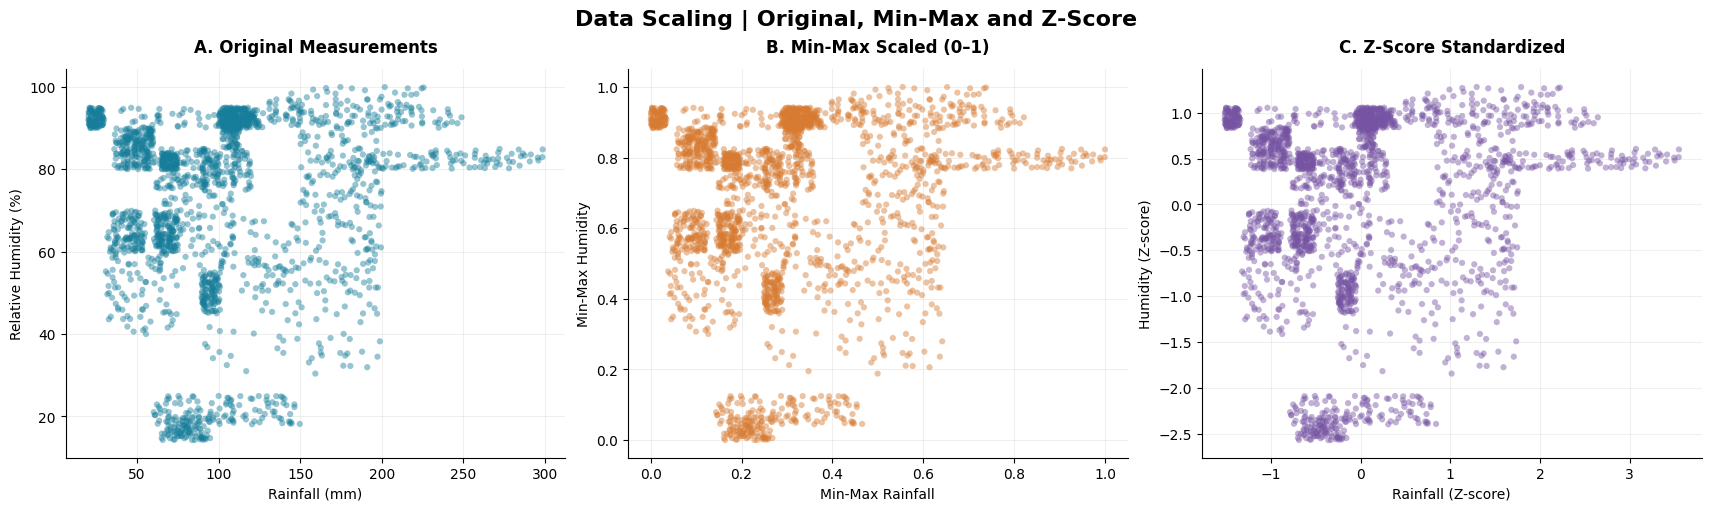

In [9]:
# Step 5.4: Visual Comparison of the Original Data and Both Scaling Methods

fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")

plot_settings = [
    (
        clustering_df["rainfall"], clustering_df["humidity"],
        "A. Original Measurements", "Rainfall (mm)", "Relative Humidity (%)", "#167D9A"
    ),
    (
        minmax_df["rainfall_minmax"], minmax_df["humidity_minmax"],
        "B. Min-Max Scaled (0–1)", "Min-Max Rainfall", "Min-Max Humidity", "#D77B32"
    ),
    (
        clustering_df["rainfall_std"], clustering_df["humidity_std"],
        "C. Z-Score Standardized", "Rainfall (Z-score)", "Humidity (Z-score)", "#7654A3"
    )
]

for ax, (x, y, title, xlabel, ylabel, color) in zip(axes, plot_settings):
    ax.scatter(x, y, s=20, alpha=0.45, color=color, edgecolors="none")
    ax.set_title(title, fontweight="bold", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

fig.suptitle(
    "Data Scaling | Original, Min-Max and Z-Score",
    fontsize=16,
    fontweight="bold"
)

plt.show()


### 5.5 Standardization Results and Method Selection

Z-score standardization was successfully applied to rainfall and humidity using the `stamn()` method demonstrated in class.

Before scaling, rainfall had a mean of 103.46 mm and standard deviation of 54.96 mm, while humidity had a mean of 71.48% and standard deviation of 22.26 percentage points.

**Min-Max scaling** maps each variable's observed minimum to 0 and maximum to 1. **Z-score standardization** centres both variables around a mean of 0 with a standard deviation of 1; Z-scores are not restricted to the range 0–1.

The comparison shows that both methods preserve each variable's ordering, but rescale their values differently. For this analysis, **we select Z-score** because equalizing the variables' standard deviations is a reasonable way to balance their influence on Euclidean distances in K-Means. Min-Max instead gives the variables equal ranges, which can lead to different relative contributions to distance.

Evidence from our data (Table 2A): after Min-Max scaling, rainfall's standard deviation is only 0.197 compared with 0.260 for humidity, because rainfall's range is stretched by a few very high values (up to 298.56 mm, mainly rice records; Table 1A). Rainfall would therefore count for less in the clustering under Min-Max. After Z-score standardization both standard deviations are exactly 1.000, so the two variables carry equal weight.

**Decision:** Section 6 continues to use only `rainfall_std` and `humidity_std`. The original measurements remain available for interpreting cluster characteristics.

**Limitation:** Neither scaling method guarantees distinct clusters, removes outliers, or makes the distributions normal.



## 6. K-Means Clustering and Elbow Method

### 6.1 Determining the Number of Clusters

K-Means is an unsupervised learning algorithm that groups observations based on their similarity.

For this analysis, we use two standardized variables:
- Rainfall
- Relative humidity

K-Means identifies cluster centres and assigns each observation to the nearest centre using Euclidean distance.

We will test different values of **K**, where K represents the number of clusters.

To help select an appropriate K, we will use the **Elbow Method**, which examines the within-cluster sum of squares (inertia).

A lower inertia indicates that observations are closer to their assigned cluster centres. However, inertia naturally decreases as K increases, so we will look for a point where the improvement starts to diminish.

Following the class demonstration, one loop fits K = 1 to 10, prints each model's centres, cluster sizes and total / between / within sums of squares, and **stores every model** so later steps reuse them.

To make the elbow easier to read, we also measure:

- **Reduction in inertia for each extra cluster** (inertia at K − 1 minus inertia at K). A large reduction means the extra cluster was worth adding; small reductions mean diminishing returns.
- **Share of variation explained** (between SS ÷ total SS), which shows how much of the total spread the clusters account for.

Finally, we compare candidate solutions with scatter plots and check cluster sizes before making our selection.


In [10]:
# Step 6.2: Evaluate K-Means Using the Elbow Method
# Use only the two standardized variables
X = clustering_df[["rainfall_std", "humidity_std"]].copy()

# Evaluate different numbers of clusters
k_values = range(1, 11)
cluster_models = {}          # reused by every later step - no refitting
inertia_values = []

total_ss = ((X - X.mean()) ** 2).to_numpy().sum()   # total sum of squares; does not depend on K


for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)
    cluster_models[k] = model
    inertia_values.append(model.inertia_)

    # Print centres, sizes and sums of squares, as in the class demonstration
    print(f"\n{'=' * 44}\nK = {k}")
    print("Centres (rainfall_std, humidity_std):")
    print(np.round(model.cluster_centers_, 3))
    print("Cluster sizes:", np.bincount(model.labels_))
    print(f"Total SS = {total_ss:,.1f} | Between SS = {total_ss - model.inertia_:,.1f} | "
          f"Within SS = {model.inertia_:,.1f}")

# Create an evaluation table for the elbow method 
elbow_results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia (WCSS)": inertia_values
})

elbow_results["Reduction from K − 1"] = -elbow_results["Inertia (WCSS)"].diff()      # gain from adding one more cluster
elbow_results["Variation Explained"] = 1 - elbow_results["Inertia (WCSS)"] / total_ss  # between SS / total SS


display(
    elbow_results.style
    .hide(axis="index")
    .format({"Inertia (WCSS)": "{:,.2f}", "Reduction from K − 1": "{:,.2f}", "Variation Explained": "{:.1%}"}, na_rep="-")
    .apply(lambda r: ["background-color: #FFF3C4; font-weight: bold" if r["Number of Clusters (K)"] == 6 else "" for _ in r], axis=1)
    .set_caption("Table 3. K-Means Inertia, Reduction per Extra Cluster and Variation Explained (K = 6 highlighted)")
)


K = 1
Centres (rainfall_std, humidity_std):
[[ 0. -0.]]
Cluster sizes: [2200]
Total SS = 4,398.0 | Between SS = 0.0 | Within SS = 4,398.0

K = 2
Centres (rainfall_std, humidity_std):
[[-0.581 -0.346]
 [ 0.934  0.556]]
Cluster sizes: [1355  845]
Total SS = 4,398.0 | Between SS = 1,618.5 | Within SS = 2,779.5

K = 3
Centres (rainfall_std, humidity_std):
[[-0.509  0.432]
 [-0.089 -1.575]
 [ 1.63   0.438]]
Cluster sizes: [1295  475  430]
Total SS = 4,398.0 | Between SS = 2,984.7 | Within SS = 1,413.3

K = 4
Centres (rainfall_std, humidity_std):
[[ 1.64   0.407]
 [-0.517 -0.558]
 [-0.006 -2.194]
 [-0.429  0.692]]
Cluster sizes: [430 557 244 969]
Total SS = 4,398.0 | Between SS = 3,367.3 | Within SS = 1,030.7

K = 5
Centres (rainfall_std, humidity_std):
[[-0.5   -0.566]
 [ 1.732  0.339]
 [-0.025 -2.211]
 [-0.944  0.628]
 [ 0.14   0.76 ]]
Cluster sizes: [552 387 240 490 531]
Total SS = 4,398.0 | Between SS = 3,640.4 | Within SS = 757.6

K = 6
Centres (rainfall_std, humidity_std):
[[-0.94   0

Number of Clusters (K),Inertia (WCSS),Reduction from K − 1,Variation Explained
1,"4,398.00",-,0.0%
2,"2,779.47","1,618.53",36.8%
3,"1,413.29","1,366.18",67.9%
4,"1,030.73",382.56,76.6%
5,757.56,273.17,82.8%
6,552.36,205.20,87.4%
7,464.59,87.77,89.4%
8,386.58,78.01,91.2%
9,328.57,58.01,92.5%
10,294.58,33.99,93.3%


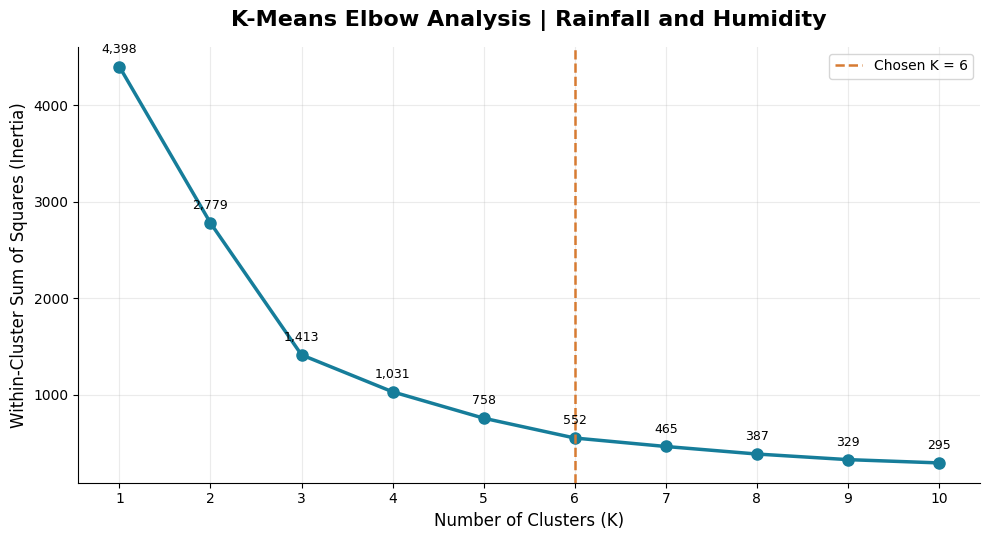

In [11]:

# Step 6.3: Elbow Method Visualization

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    elbow_results["Number of Clusters (K)"],
    elbow_results["Inertia (WCSS)"],
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#167D9A"
)

ax.set_title(
    "K-Means Elbow Analysis | Rainfall and Humidity",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Clusters (K)", fontsize=12)
ax.set_ylabel("Within-Cluster Sum of Squares (Inertia)", fontsize=12)

ax.axvline(6, color="#D77B32", linestyle="--", linewidth=1.8, label="Chosen K = 6")
ax.legend()

ax.set_xticks(list(k_values))
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

# Display actual inertia values
for k, inertia in zip(k_values, inertia_values):
    ax.annotate(
        f"{inertia:,.0f}",
        (k, inertia),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

sns.despine(ax=ax)
plt.tight_layout()
plt.show()


Step,Reduction from K − 1
1 → 2,"1,618.53"
2 → 3,"1,366.18"
3 → 4,382.56
4 → 5,273.17
5 → 6,205.20
6 → 7,87.77
7 → 8,78.01
8 → 9,58.01
9 → 10,33.99


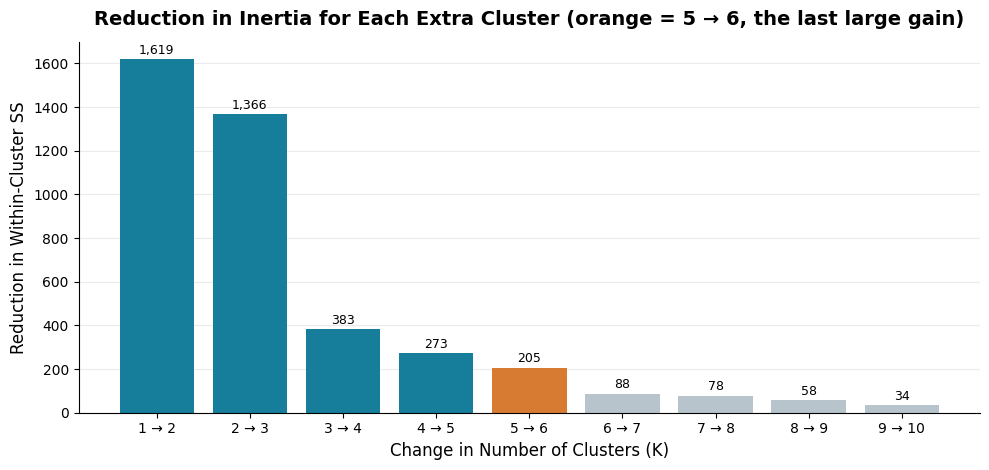

In [12]:
# Step 6.4: Reduction in Inertia for Each Extra Cluster (makes the elbow measurable)
# A large bar means the extra cluster was worth adding; small bars mean diminishing returns

reductions = elbow_results.dropna().copy()
reductions["Step"] = [f"{k - 1} → {k}" for k in reductions["Number of Clusters (K)"]]

display(
    reductions[["Step", "Reduction from K − 1"]].style
    .hide(axis="index")
    .format({"Reduction from K − 1": "{:,.2f}"})
    .apply(lambda r: ["background-color: #FFF3C4; font-weight: bold" if r["Step"] == "5 → 6" else "" for _ in r], axis=1)
    .set_caption("Table 4. Reduction in Inertia (WCSS) for Each Extra Cluster")
)

colors = ["#D77B32" if k == 6 else ("#B8C4CC" if k > 6 else "#167D9A")
          for k in reductions["Number of Clusters (K)"]]

fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.bar(reductions["Step"], reductions["Reduction from K − 1"], color=colors)
for bar, value in zip(bars, reductions["Reduction from K − 1"]):
    ax.annotate(f"{value:,.0f}", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_title("Reduction in Inertia for Each Extra Cluster (orange = 5 → 6, the last large gain)",
             fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Change in Number of Clusters (K)", fontsize=12)
ax.set_ylabel("Reduction in Within-Cluster SS", fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

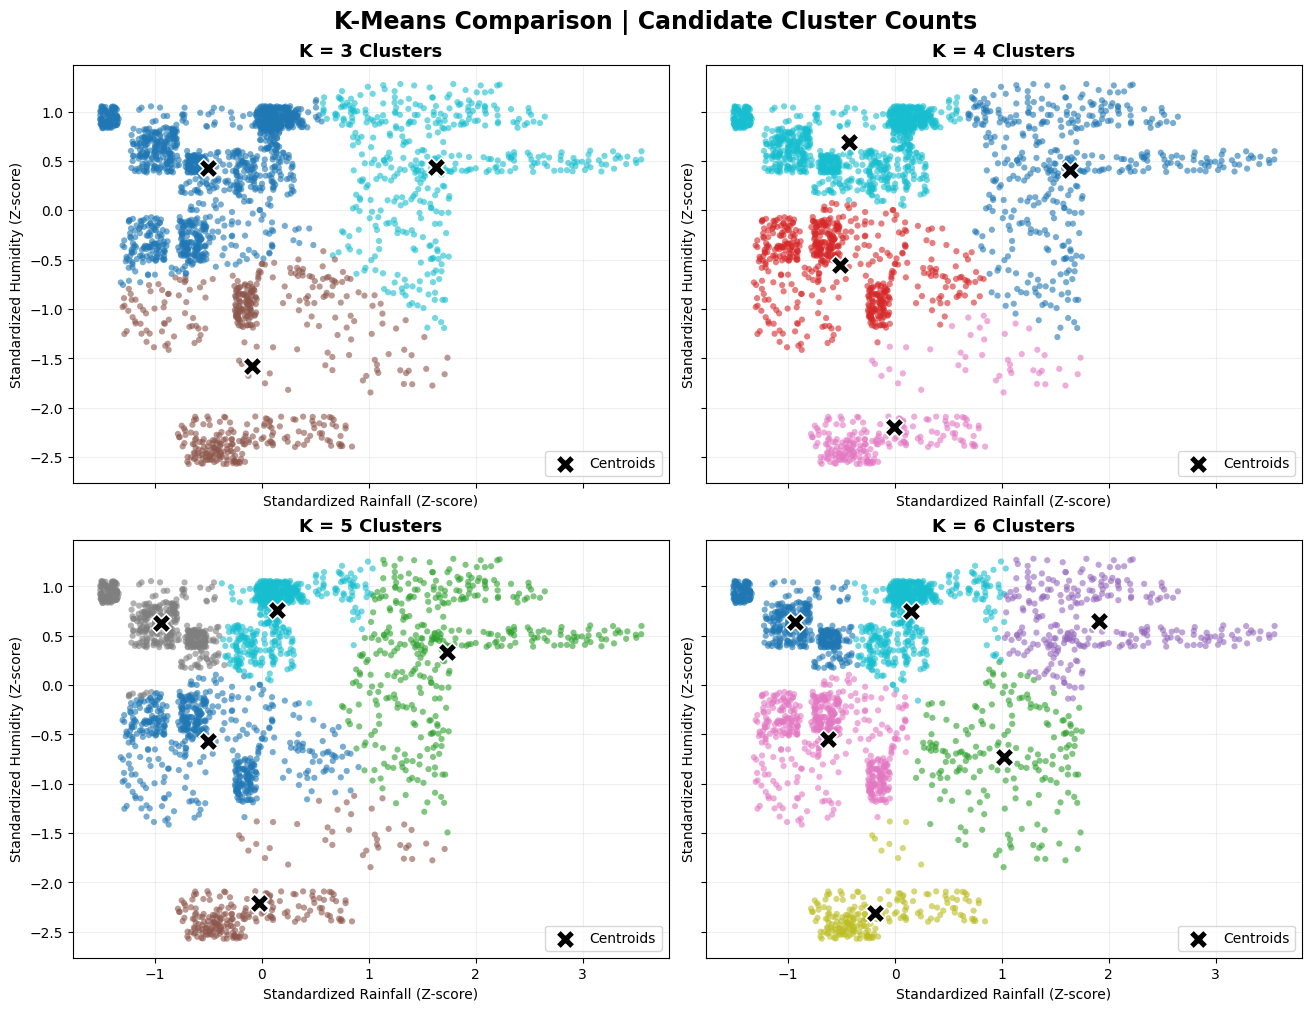

In [13]:
# Step 6.5: Visual Comparison of Candidate K-Means Solutions

candidate_k = [3, 4, 5, 6]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    sharex=True,
    sharey=True,
    layout="constrained"
)

for ax, k in zip(axes.flat, candidate_k):

    model = cluster_models[k]          # stored model from Step 6.2 - no refitting
    labels = model.labels_
    centers = model.cluster_centers_

    scatter = ax.scatter(
        X["rainfall_std"],
        X["humidity_std"],
        c=labels,
        cmap="tab10",
        s=20,
        alpha=0.6,
        edgecolors="none"
    )

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker="X",
        s=190,
        c="black",
        edgecolors="white",
        linewidths=1.2,
        label="Centroids",
        zorder=5
    )

    ax.set_title(
        f"K = {k} Clusters",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Standardized Rainfall (Z-score)")
    ax.set_ylabel("Standardized Humidity (Z-score)")
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right")

fig.suptitle(
    "K-Means Comparison | Candidate Cluster Counts",
    fontsize=17,
    fontweight="bold"
)

plt.show()

In [14]:
# Step 6.6: Shortlist Validation (stored models from Step 6.2, all 2,200 observations)

validation_results = []

for k in [3, 4, 5, 6]:
    model = cluster_models[k]          # stored model - no refitting
    cluster_sizes = np.bincount(model.labels_, minlength=k)

    validation_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Reduction from K − 1": cluster_models[k - 1].inertia_ - model.inertia_,
        "Variation Explained": 1 - model.inertia_ / total_ss,
        "Smallest Cluster": cluster_sizes.min(),
        "Largest Cluster": cluster_sizes.max()
    })

validation_df = pd.DataFrame(validation_results)

display(
    validation_df.style
    .hide(axis="index")
    .format({
        "Inertia": "{:,.2f}",
        "Reduction from K − 1": "{:,.2f}",
        "Variation Explained": "{:.1%}",
        "Smallest Cluster": "{:,.0f}",
        "Largest Cluster": "{:,.0f}"
    })
    .apply(lambda r: ["background-color: #FFF3C4" if r["K"] == 6 else "" for _ in r], axis=1)
    .set_caption(
        "Table 5. Shortlist Validation (K = 3–6, 2,200 Observations)"
    )
)

K,Inertia,Reduction from K − 1,Variation Explained,Smallest Cluster,Largest Cluster
3,"1,413.29","1,366.18",67.9%,430,"1,295"
4,"1,030.73",382.56,76.6%,244,969
5,757.56,273.17,82.8%,240,552
6,552.36,205.20,87.4%,190,541


### 6.7 Final Cluster Count Recommendation

We evaluated K-Means models using the elbow method (inertia, the reduction in inertia for each extra cluster, and the share of variation explained), together with cluster sizes and scatter plots.

The elbow chart suggested an early bend near K = 3, where the rate of inertia reduction began to slow. However, additional cluster counts continued to improve within-cluster compactness substantially (Tables 3 and 4):

- Going from 3 to 4 clusters reduces inertia by 382.6, from 4 to 5 by 273.2, and from 5 to 6 still by **205.2**.
- Going from 6 to 7 reduces it by only **87.8**, less than half the 5 → 6 gain, and every later step reduces it by less than 80.
- So **K = 6 is the last point where adding a cluster gives a large improvement**: the final clear bend in the elbow.

At K = 6 the clusters explain **87.4 %** of the total variation in the two standardized variables, compared with 67.9 % at K = 3; K = 7 would add only 2 percentage points. K = 6 has an inertia of 552.36, and its cluster sizes range from 190 to 541 observations (Table 5).

The K = 6 scatter plot also showed more detailed separation of rainfall–humidity patterns than the simpler alternatives: K = 3 and K = 4 combine records with very different rainfall levels in the high-humidity band.

**Recommended clustering scheme:** K = 6, using standardized rainfall and relative humidity.

**Justification:** K = 6 is the last clear bend in the elbow, explains most of the variation, has reasonable cluster sizes and gives potentially interpretable environmental patterns.

**Limitation:** The elbow method does not identify a single unambiguous K (there is also an earlier bend at K = 3), and a good statistical fit does not guarantee agricultural usefulness. The recommendation will be assessed further by examining the cluster profiles and crop-label distributions.


## 7. Final Clustering Scheme: Summary of the Clusters

We take the stored K = 6 model, assign every record to a cluster, and summarize **all** the data by cluster: every soil and climate variable in original units, and the crop labels in each cluster.

**Naming the clusters.** K-Means numbers clusters arbitrarily. We name each cluster **only from what was used to build it**: its centre humidity and rainfall, converted back to % and mm and placed in descriptive bands.

| Humidity band | Centre humidity | Rainfall band | Centre rainfall |
|---|---|---|---|
| Very Low Humidity | below 40 % | Low Rainfall | below 80 mm |
| Moderate Humidity | 40–70 % | Moderate Rainfall | 80–130 mm |
| High Humidity | 70 % or more | High Rainfall | 130–180 mm |
| | | Very High Rainfall | 180 mm or more |

These bands are descriptive labels chosen for this dataset's cluster centres. They are not agronomic or climate-classification standards, and the rainfall accumulation period is not specified in the source.

**Numbering.** Clusters are numbered by **humidity band first** (very low → moderate → high), then **by centre rainfall within each band** (low → high). This is not a single dry-to-wet scale: for example, cluster 3 has more rainfall than clusters 4 and 5 but lower humidity.

In [15]:
# Step 7.1: Take the final model and name the clusters from their measured centres
FINAL_K = 6
final_model = cluster_models[FINAL_K]          # reuse the stored model from Step 6.2
clustering_df["cluster_id"] = final_model.labels_

# Cluster centres back in original units (X columns: rainfall_std, humidity_std)
centres = pd.DataFrame(final_model.cluster_centers_, columns=["rainfall_std", "humidity_std"])
centres["rainfall"] = centres["rainfall_std"] * clean_df["rainfall"].std() + clean_df["rainfall"].mean()
centres["humidity"] = centres["humidity_std"] * clean_df["humidity"].std() + clean_df["humidity"].mean()

# Descriptive bands (upper limit, label) - based only on the two clustering variables
HUMIDITY_BANDS = [(40, "Very Low Humidity"), (70, "Moderate Humidity"), (float("inf"), "High Humidity")]
RAINFALL_BANDS = [(80, "Low Rainfall"), (130, "Moderate Rainfall"), (180, "High Rainfall"),
                  (float("inf"), "Very High Rainfall")]

def band(value, bands):
    for rank, (upper, label) in enumerate(bands):
        if value < upper:
            return rank, label

centres["humidity_rank"], centres["Humidity Band"] = zip(*centres["humidity"].map(lambda v: band(v, HUMIDITY_BANDS)))
centres["Rainfall Band"] = centres["rainfall"].map(lambda v: band(v, RAINFALL_BANDS)[1])
centres["Cluster Name"] = centres["Humidity Band"] + ", " + centres["Rainfall Band"]
assert centres["Cluster Name"].is_unique, "Each cluster must get a unique name"

# Number clusters: humidity band first (very low -> high), then centre rainfall within the band (low -> high)
centres = centres.sort_values(["humidity_rank", "rainfall"])
centres["Cluster"] = range(1, FINAL_K + 1)
NAME_ORDER = centres["Cluster Name"].tolist()
order = dict(zip(NAME_ORDER, centres["Cluster"]))

# Attach clusters to the full dataset
clean_df["cluster"] = clustering_df["cluster_id"].map(centres["Cluster"])
clean_df["cluster_name"] = pd.Categorical(clustering_df["cluster_id"].map(centres["Cluster Name"]),
                                          categories=NAME_ORDER, ordered=True)

display(
    centres[["Cluster", "Cluster Name", "rainfall_std", "humidity_std", "rainfall", "humidity"]]
    .rename(columns={"rainfall_std": "Centre Rainfall (Z)", "humidity_std": "Centre Humidity (Z)",
                     "rainfall": "Centre Rainfall (mm)", "humidity": "Centre Humidity (%)"})
    .style.hide(axis="index").format(precision=2)
    .set_caption("Table 6. Final Cluster Centres and Names (Standardized and Original Units)")
)

Cluster,Cluster Name,Centre Rainfall (Z),Centre Humidity (Z),Centre Rainfall (mm),Centre Humidity (%)
1,"Very Low Humidity, Moderate Rainfall",-0.18,-2.31,93.39,19.95
2,"Moderate Humidity, Low Rainfall",-0.63,-0.55,68.80,59.31
3,"Moderate Humidity, High Rainfall",1.02,-0.73,159.56,55.22
4,"High Humidity, Low Rainfall",-0.94,0.64,51.82,85.77
5,"High Humidity, Moderate Rainfall",0.15,0.75,111.56,88.20
6,"High Humidity, Very High Rainfall",1.91,0.65,208.26,85.93


In [16]:

# Step 7.2: Summary of clusters using ALL numerical data (NUMERIC_COLS and LABELS come from the setup cell)
summary_all = clean_df.groupby("cluster_name", observed=True)[NUMERIC_COLS].mean()
summary_all.insert(0, "Records", clean_df["cluster_name"].value_counts().reindex(NAME_ORDER).values)
summary_all.insert(1, "% of Data", summary_all["Records"] / len(clean_df) * 100)

# Crop labels with at least half of their 100 records in the cluster (describes where records sit, not suitability)
crop_share = pd.crosstab(clean_df["label"], clean_df["cluster_name"], normalize="index")
summary_all["Crop Labels Mostly in This Cluster (≥50% of the label's records)"] = [
    ", ".join(f"{crop} ({crop_share.loc[crop, name]:.0%})"
              for crop in crop_share[name][crop_share[name] >= 0.5].sort_values(ascending=False).index)
    for name in summary_all.index
]
summary_all.columns = ["Records", "% of Data"] + [LABELS[c] for c in NUMERIC_COLS] + \
                      ["Crop Labels Mostly in This Cluster (≥50% of the label's records)"]

display(
    summary_all.style
    .format({c: "{:.1f}" for c in summary_all.columns if c not in ["Records", "Crop Labels Mostly in This Cluster (≥50% of the label's records)"]})
    .set_caption("Table 7. Cluster Summary: Means of All Variables in Original Units")
)

overall = clean_df[NUMERIC_COLS].mean().to_frame("All Records").T
overall.columns = [LABELS[c] for c in NUMERIC_COLS]
display(overall.style.format("{:.1f}").set_caption("Table 7A. Overall Means for Comparison"))

,Records,% of Data,Nitrogen (ratio),Phosphorus (ratio),Potassium (ratio),Temperature (°C),Relative Humidity (%),Soil pH,Rainfall (mm),Crop Labels Mostly in This Cluster (≥50% of the label's records)
cluster_name,,,,,,,,,,
"Very Low Humidity, Moderate Rainfall",209,9.5,30.0,67.6,48.7,19.8,20.0,6.5,93.4,"chickpea (100%), kidneybeans (100%)"
"Moderate Humidity, Low Rainfall",500,22.7,34.4,52.4,21.7,27.4,59.3,6.6,68.8,"blackgram (100%), lentil (100%), mango (100%), mothbeans (100%), maize (89%)"
"Moderate Humidity, High Rainfall",190,8.6,65.6,46.4,26.7,26.3,55.2,6.4,159.6,"coffee (97%), pigeonpeas (80%)"
"High Humidity, Low Rainfall",481,21.9,67.0,53.1,71.5,26.6,85.8,6.5,51.8,"grapes (100%), muskmelon (100%), mungbean (100%), watermelon (100%), cotton (56%)"
"High Humidity, Moderate Rainfall",541,24.6,47.8,57.0,63.8,24.7,88.2,6.4,111.6,"apple (100%), banana (100%), orange (100%), pomegranate (100%)"
"High Humidity, Very High Rainfall",279,12.7,61.6,42.5,39.2,26.4,85.9,6.5,208.3,"rice (100%), jute (73%), coconut (61%)"


,Nitrogen (ratio),Phosphorus (ratio),Potassium (ratio),Temperature (°C),Relative Humidity (%),Soil pH,Rainfall (mm)
All Records,50.6,53.4,48.1,25.6,71.5,6.5,103.5


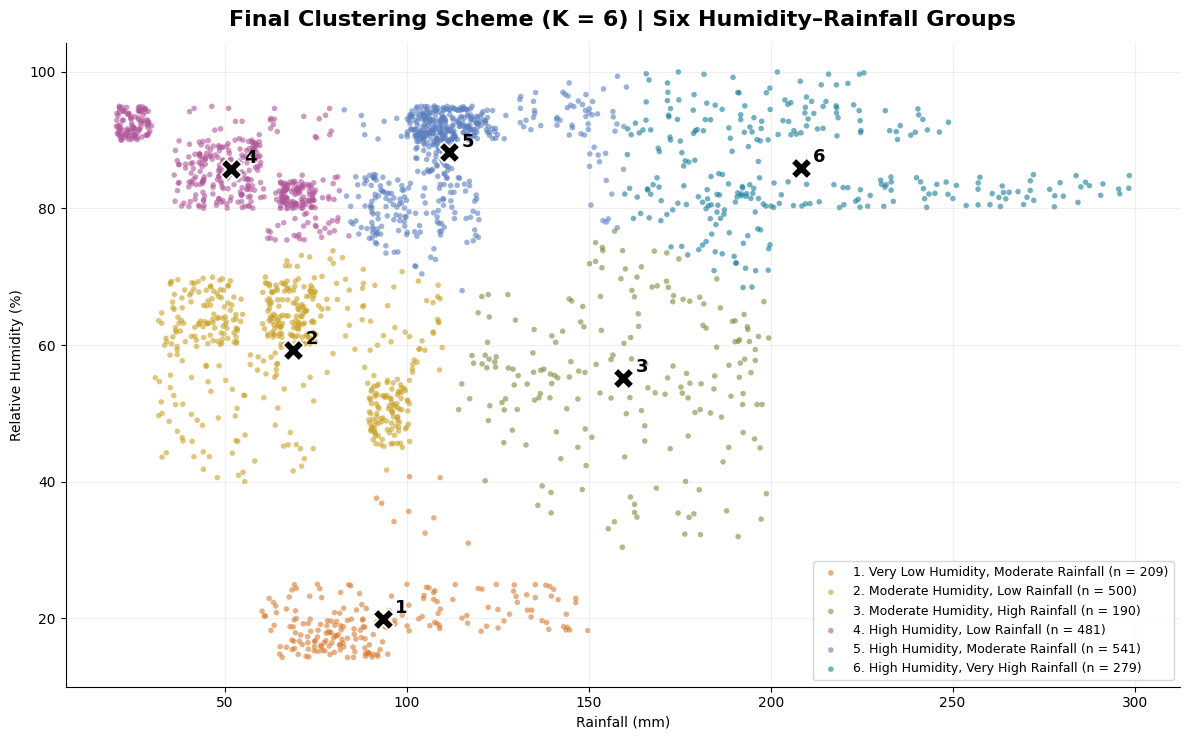

In [17]:
# Step 7.3: Final clustering scheme in original units
palette = dict(zip(NAME_ORDER, ["#D77B32", "#C9A227", "#7A8B3C", "#B0569A", "#5B7FBF", "#167D9A"]))

fig, ax = plt.subplots(figsize=(12, 7.5))
for name in NAME_ORDER:
    subset = clean_df[clean_df["cluster_name"] == name]
    ax.scatter(subset["rainfall"], subset["humidity"], s=16, alpha=0.6, color=palette[name],
               edgecolors="none", label=f"{order[name]}. {name} (n = {len(subset)})")

for _, c in centres.iterrows():
    ax.scatter(c["rainfall"], c["humidity"], marker="X", s=230, color="black",
               edgecolors="white", linewidths=1.2, zorder=5)
    ax.annotate(str(c["Cluster"]), (c["rainfall"], c["humidity"]), xytext=(9, 4),
                textcoords="offset points", fontsize=13, fontweight="bold")

ax.set_title("Final Clustering Scheme (K = 6) | Six Humidity–Rainfall Groups", fontsize=16, fontweight="bold", pad=12)
ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Relative Humidity (%)")
ax.legend(loc="lower right", fontsize=9, frameon=True)
ax.grid(alpha=0.2)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

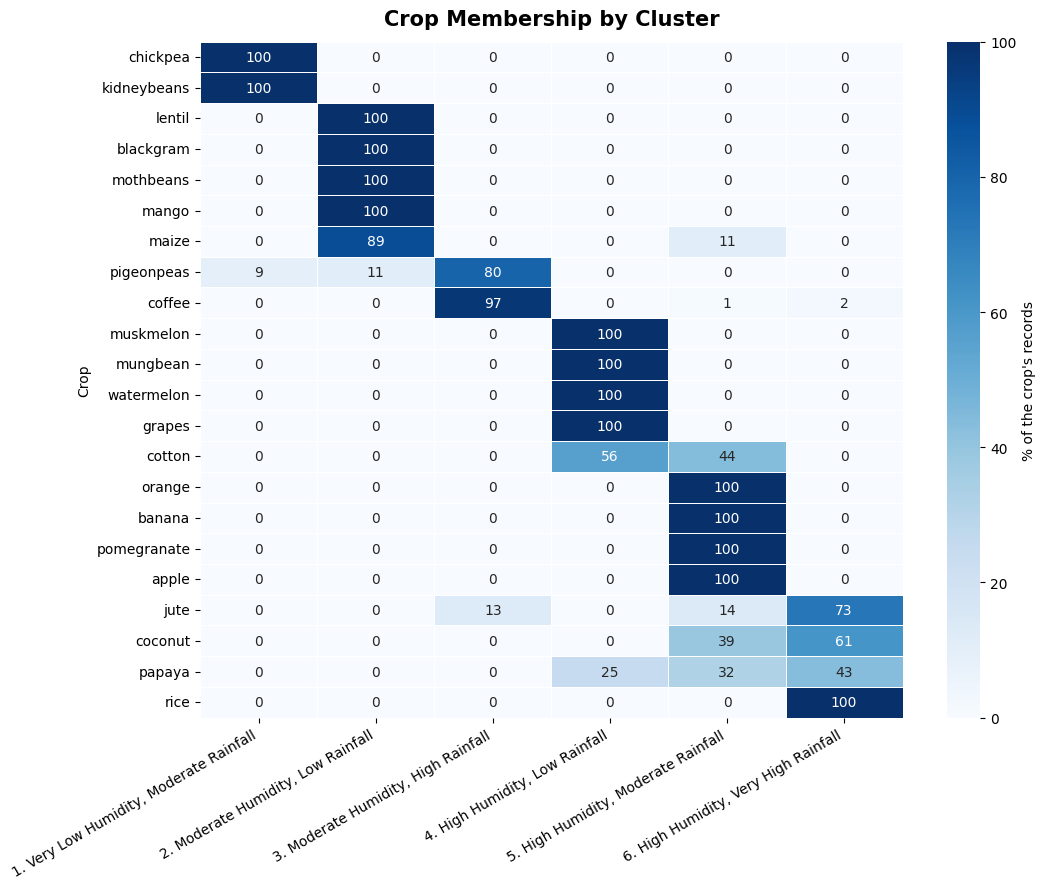

In [18]:
# Step 7.4: Which crops fall in which cluster? (% of each crop's 100 records)
crop_order = crop_share.idxmax(axis=1).map(order).sort_values().index

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap((crop_share.loc[crop_order] * 100).round(0), annot=True, fmt=".0f", cmap="Blues",
            linewidths=0.5, cbar_kws={"label": "% of the crop's records"}, ax=ax)
ax.set_xticklabels([f"{order[n]}. {n}" for n in NAME_ORDER], rotation=30, ha="right")
ax.set_title("Crop Membership by Cluster", fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Crop")
plt.tight_layout()
plt.show()

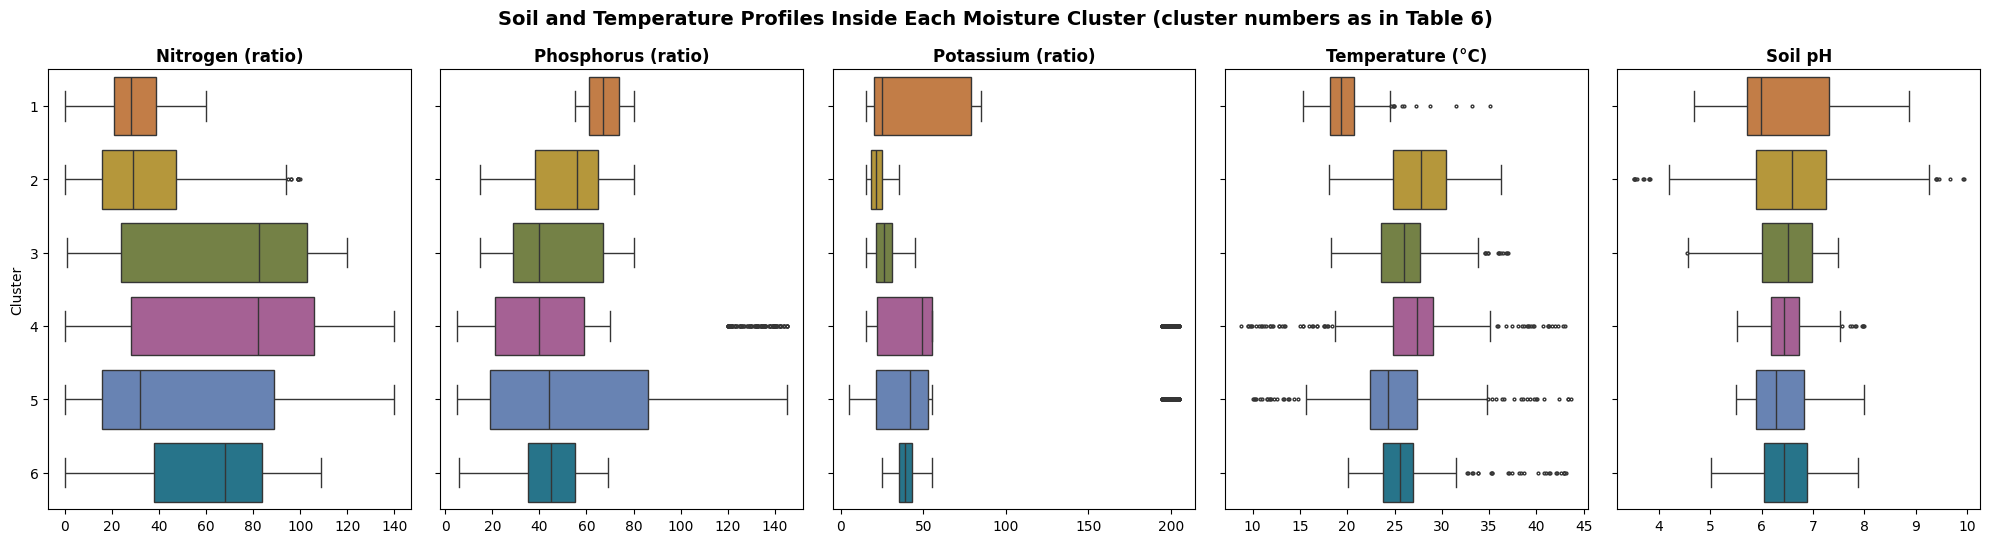

In [19]:
# Step 7.5: Profiles of the variables NOT used to build the clusters
profile_vars = ["N", "P", "K", "temperature", "ph"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5.5), sharey=True)
for ax, var in zip(axes, profile_vars):
    sns.boxplot(data=clean_df, x=var, y="cluster", hue="cluster", orient="h",
                palette=[palette[n] for n in NAME_ORDER], legend=False, fliersize=2, ax=ax)
    ax.set_title(LABELS[var], fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Cluster" if var == "N" else "")
fig.suptitle("Soil and Temperature Profiles Inside Each Moisture Cluster "
             "(cluster numbers as in Table 6)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

profile_table = clean_df.groupby("cluster_name", observed=True)[profile_vars].agg(["mean", "std"])
display(profile_table.style.format("{:.1f}")
        .set_caption("Table 8. Mean and Standard Deviation of Non-Clustering Variables by Cluster"))

### 7.6 Cluster Names and Descriptions

| # | Cluster Name | Size | Centre (humidity, rainfall) | Crop Labels Mostly in This Cluster | Other Differences (cluster means) |
|---|---|---|---|---|---|
| 1 | **Very Low Humidity, Moderate Rainfall** | 209 (9.5 %) | ~20 %, ~93 mm | chickpea, kidney beans (100 % of each label's records) | Lowest mean temperature (~20 °C); lowest nitrogen (~30) and highest phosphorus (~68) |
| 2 | **Moderate Humidity, Low Rainfall** | 500 (22.7 %) | ~59 %, ~69 mm | moth beans, black gram, lentil, mango (100 %), maize (89 %) | Highest mean temperature (~27 °C); lowest potassium (~22) |
| 3 | **Moderate Humidity, High Rainfall** | 190 (8.6 %) | ~55 %, ~160 mm | coffee (97 %), pigeon peas (80 %) | High nitrogen (~66), low potassium (~27) |
| 4 | **High Humidity, Low Rainfall** | 481 (21.9 %) | ~86 %, ~52 mm | mung bean, grapes, watermelon, muskmelon (100 %), cotton (56 %) | Highest mean nitrogen (~67) and potassium (~72) |
| 5 | **High Humidity, Moderate Rainfall** | 541 (24.6 %) | ~88 %, ~112 mm | pomegranate, banana, apple, orange (100 %) | High mean potassium (~64, driven by apple) |
| 6 | **High Humidity, Very High Rainfall** | 279 (12.7 %) | ~86 %, ~208 mm | rice (100 %), jute (73 %), coconut (61 %); papaya's largest share (43 %) | High nitrogen (~62); lowest phosphorus (~43) |

**How to read the crop column:** it shows where each crop label's records fall in this dataset. The labels are *recommended* crops in an augmented teaching dataset, so a crop appearing in a cluster does **not** show that the crop requires, prefers or performs best under those conditions.

### 7.7 Insights Gained From the Clusters

1. **22 crop labels map onto six humidity–rainfall groups.** Using only two climate variables and no crop labels, K-Means sorts 2,200 records into six groups that explain 87.4 % of the variation in the two standardized variables (Table 3). For 15 of the 22 labels, all records fall in a single cluster, and every label except papaya has more than half of its records in one cluster. This gives a compact way to describe the recorded conditions in this dataset.
2. **The rice–maize difference from Workshop A fits a wider pattern.** Rice records sit in *High Humidity, Very High Rainfall* and maize records mostly in *Moderate Humidity, Low Rainfall*. The 151.41 mm mean rainfall gap we tested earlier is consistent with the two labels being recorded under clearly different moisture conditions in this dataset. It does not establish what either crop needs.
3. **Clusters group conditions, not crop types.** Pulse records are spread across four clusters: chickpea and kidney beans in cluster 1; moth beans, black gram and lentil in cluster 2; mung bean in cluster 4; and pigeon peas mostly in cluster 3. Mango records sit with the cluster 2 pulses, while apple, orange, banana and pomegranate share cluster 5. In this dataset, crop type alone does not indicate the recorded moisture conditions.
4. **Humidity forms three broad bands and rainfall subdivides them.** On the final scatter plot, the chickpea and kidney-bean records (humidity 14–25 %) stand well apart; only a thin scatter of pigeon-pea records (about 30–40 %) bridges the gap. Clusters 2 and 3 share the moderate-humidity band and differ in rainfall, and clusters 4, 5 and 6 almost all sit above 75 % humidity and differ mainly in rainfall.
5. **Other variables differ between clusters, even though they were not used to build them.** Cluster 1 has the lowest mean nitrogen and highest mean phosphorus; cluster 4 has the highest mean nitrogen and potassium. Mean temperature ranges from about 20 °C (cluster 1) to 27 °C (cluster 2). Soil pH is almost the same in every cluster (about 6.4–6.6). These are associations within this dataset. They do not show that humidity or rainfall cause these soil levels, or that crops need them.
6. **Some labels span more than one cluster.** Papaya records are split 25 / 32 / 43 % across clusters 4–6, and cotton (56 / 44 %), coconut (61 / 39 %), jute and pigeon peas also appear in two or more clusters. These labels have a wider range of recorded conditions here. Whether the crops would perform well across that range cannot be judged from this dataset and would need field or yield data.

## 8. Final Recommended Clustering Scheme

| Decision | Recommendation | Justification |
|---|---|---|
| **Variables** | Rainfall and relative humidity | Together they describe the recorded moisture conditions and continue the water theme of Assignments 1–2 and Workshop A. They are almost uncorrelated (r = 0.094, Section 4.2), so each adds separate information, and the rainfall–humidity scatter plot shows more visible concentrations than rainfall–temperature. They are site conditions a planner must work with, not fertilizer-managed values like N, P and K. |
| **Standardization** | Z-score (`stamn()`) | Gives both variables a standard deviation of exactly 1, so each has equal weight in Euclidean distance (Table 2). Under Min-Max, rainfall's standard deviation would be only 0.197 against 0.260 for humidity (Table 2A), because its range is stretched by a few very high values (up to 298.56 mm, Table 1); rainfall would then count for less in the clustering. |
| **Algorithm** | K-Means, `n_init = 10`, `random_state = 42` | The method demonstrated in class; ten random starts avoid poor local solutions and the fixed seed makes the results reproducible. |
| **Number of clusters** | **K = 6** | **Elbow method:** after the early bend at K = 3, inertia keeps falling substantially until K = 6. The 5 → 6 step reduces it by 205.2, but the 6 → 7 step by only 87.8 (less than half) and every later step by less than 80 (Tables 3–4). K = 6 explains 87.4 % of the variation, and K = 7 would add only 2 percentage points (Table 3). Also: reasonable cluster sizes (190–541, Table 5); the clearest separation among the K = 3–6 scatter plots (Step 6.5); and every cluster can be described clearly. |
| **Cluster names** | Very Low Humidity, Moderate Rainfall · Moderate Humidity, Low Rainfall · Moderate Humidity, High Rainfall · High Humidity, Low Rainfall · High Humidity, Moderate Rainfall · High Humidity, Very High Rainfall | Based only on each cluster's centre humidity and rainfall (Section 7 bands), so the names describe what was measured rather than implying geography or crop suitability. |

### Limitations

- The dataset is **augmented and perfectly balanced** (100 records per crop). Cluster sizes reflect how many crop labels share similar recorded conditions, not how much farmland has those conditions.
- There are no locations, dates, elevations or rainfall accumulation periods, so the clusters describe recorded conditions in this dataset, not measured fields or regions. Local, representative data would be needed before any policy use.
- Crop labels are *recommended* crops, not yields or outcomes, so cluster membership cannot show which crops grow best under which conditions.
- K-Means assumes roughly round, similar-sized clusters. The high-humidity band is continuous, so the boundaries between clusters 4, 5 and 6 are partly where K-Means draws the line; the scatter plots make this visible.



## 9. Final Conclusion

In this workshop, our goal was to find groups of crop records with similar growing conditions instead of looking at each crop separately. In our previous assignments, we explored the dataset and compared individual crops, such as rice and maize. This time, we wanted to understand the bigger patterns across the whole dataset.

We used K-Means clustering on 2,200 records from 22 crop types. We selected rainfall and humidity because both describe moisture-related growing conditions. After comparing different numbers of clusters using the elbow method, scatter plots, and other results, we selected **K = 6**. These six clusters explained **87.4% of the variation** in our two standardized variables.

The results showed that different crops can share similar recorded growing conditions. For example, apple, orange, banana, and pomegranate were grouped together in one cluster. We also found that rice records belonged to a group with high humidity and very high rainfall, while most maize records belonged to a group with moderate humidity and low rainfall. This helped us understand the rainfall difference between rice and maize that we studied in our previous assignment.

Another important finding was that not every crop belonged to just one group. Some crops, such as papaya, had records spread across different clusters. This shows that the dataset contains a wider range of recorded conditions for some crop types.

**Overall, we achieved our main goal.** We identified six useful groups of rainfall and humidity conditions and discovered how the 22 crop labels were distributed across those groups. Instead of only comparing crops one by one, we now have a clearer picture of their similarities and differences across the whole dataset.

However, our results only describe patterns in this dataset. They do not prove which crops will grow best in a particular location. More information, such as real farm locations, seasons, and crop yields, would be needed before making farming recommendations.

This analysis gives our Crop Recommendation project a useful starting point for understanding environmental patterns and exploring crop recommendations further.